In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


filename = "Concrete_Data_updated.xls"
data_csv = pd.read_excel(filename)
print(data_csv)

      Cement (component 1)(kg in a m^3 mixture)  \
0                                         540.0   
1                                         540.0   
2                                         332.5   
3                                         332.5   
4                                         198.6   
...                                         ...   
1025                                      276.4   
1026                                      322.2   
1027                                      148.5   
1028                                      159.1   
1029                                      260.9   

      Blast Furnace Slag (component 2)(kg in a m^3 mixture)  \
0                                                   0.0       
1                                                   0.0       
2                                                 142.5       
3                                                 142.5       
4                                                 132.4       
...      

In [3]:
# 2. Check for missing values

total_nans = data_csv.isna().sum().sum()

if total_nans == 0:
    print("\nNo NaN values found in the dataset.")
else:
    print("\nNaN values by column:")
    print(data_csv.isna().sum())

    raise ValueError(
        f"Found {total_nans} NaN values. "
        "Handle the missing values before training the model."
    )

# 3. Check for and remove duplicate rows

num_duplicates = data_csv.duplicated().sum()
print(f"\nNumber of duplicate rows: {num_duplicates}")

data_csv = data_csv.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", data_csv.shape)


No NaN values found in the dataset.

Number of duplicate rows: 25
Dataset shape after removing duplicates: (1005, 9)


In [6]:

# 4. Calculate cost

# Cost factors in AUD/kg
CEMENT_COST = 0.44
BLAST_FURNACE_SLAG_COST = 0.086
FLY_ASH_COST = 0.876
WATER_COST = 0.000115
SUPERPLASTICIZER_COST = 7.66
COARSE_AGGREGATE_COST = 0.09
FINE_AGGREGATE_COST = 0.08

data_csv["Cost per m^3"] = (
    data_csv["Cement (component 1)(kg in a m^3 mixture)"]
    * CEMENT_COST

    + data_csv["Blast Furnace Slag (component 2)(kg in a m^3 mixture)"]
    * BLAST_FURNACE_SLAG_COST

    + data_csv["Fly Ash (component 3)(kg in a m^3 mixture)"]
    * FLY_ASH_COST

    + data_csv["Water  (component 4)(kg in a m^3 mixture)"]
    * WATER_COST

    + data_csv["Superplasticizer (component 5)(kg in a m^3 mixture)"]
    * SUPERPLASTICIZER_COST

    + data_csv["Coarse Aggregate  (component 6)(kg in a m^3 mixture)"]
    * COARSE_AGGREGATE_COST

    + data_csv["Fine Aggregate (component 7)(kg in a m^3 mixture)"]
    * FINE_AGGREGATE_COST
)

print("\nCalculated cost:")
print(data_csv[["Cost per m^3"]])


# 5. Calculate CO2 emissions

# Emission factors in kg CO2e/kg
CEMENT_CO2 = 966.9 / 1000
BLAST_FURNACE_SLAG_CO2 = 192.2 / 1000
FLY_ASH_CO2 = 19.8 / 1000
WATER_CO2 = 0.4 / 1000
SUPERPLASTICIZER_CO2 = 4.73 / 1000
COARSE_AGGREGATE_CO2 = 10.5 / 1000
FINE_AGGREGATE_CO2 = 4.2 / 1000

data_csv["CO2_Emissions"] = (
    data_csv["Cement (component 1)(kg in a m^3 mixture)"]
    * CEMENT_CO2

    + data_csv["Blast Furnace Slag (component 2)(kg in a m^3 mixture)"]
    * BLAST_FURNACE_SLAG_CO2

    + data_csv["Fly Ash (component 3)(kg in a m^3 mixture)"]
    * FLY_ASH_CO2

    + data_csv["Water  (component 4)(kg in a m^3 mixture)"]
    * WATER_CO2

    + data_csv["Superplasticizer (component 5)(kg in a m^3 mixture)"]
    * SUPERPLASTICIZER_CO2

    + data_csv["Coarse Aggregate  (component 6)(kg in a m^3 mixture)"]
    * COARSE_AGGREGATE_CO2

    + data_csv["Fine Aggregate (component 7)(kg in a m^3 mixture)"]
    * FINE_AGGREGATE_CO2
)

print("\nCalculated CO2 emissions:")
print(data_csv[["CO2_Emissions"]])


Calculated cost:
      Cost per m^3
0       404.448630
1       405.798630
2       289.981220
3       289.981220
4       252.888480
...            ...
1000    418.662454
1001    461.403140
1002    361.926160
1003    324.814394
1004    396.653869

[1005 rows x 1 columns]

Calculated CO2 emissions:
      CO2_Emissions
0        535.961825
1        536.119325
2        361.254750
3        361.254750
4        231.290720
...             ...
1000     303.811147
1001     325.955882
1002     185.279743
1003     203.545399
1004     285.527118

[1005 rows x 1 columns]


In [7]:
# 6. Check variance

numeric_variance = data_csv.var(numeric_only=True)
print("\nVariance of numeric columns:")
print(numeric_variance)

constant_columns = numeric_variance[numeric_variance == 0].index.tolist()

if len(constant_columns) == 0:
    print("\nNo constant numeric columns were found.")
else:
    print("\nConstant columns:", constant_columns)


Variance of numeric columns:
Cement (component 1)(kg in a m^3 mixture)                10887.879601
Blast Furnace Slag (component 2)(kg in a m^3 mixture)     7425.364576
Fly Ash (component 3)(kg in a m^3 mixture)                4122.596436
Water  (component 4)(kg in a m^3 mixture)                  455.427169
Superplasticizer (component 5)(kg in a m^3 mixture)         35.041179
Coarse Aggregate  (component 6)(kg in a m^3 mixture)      6018.584052
Fine Aggregate (component 7)(kg in a m^3 mixture)         6454.491667
Age (day)                                                 4062.110923
Concrete compressive strength(MPa, megapascals)            265.194960
Cost per m^3                                              7135.832450
CO2_Emissions                                             9288.685441
dtype: float64

No constant numeric columns were found.



Test-set performance:
MAE: 8.896027820458997
RMSE: 11.19219988548833
R²: 0.5801089019953831

Intercept: -23.232830596155395

Regression coefficients:
                                             Feature  Coefficient
0          Cement (component 1)(kg in a m^3 mixture)     0.116647
1  Blast Furnace Slag (component 2)(kg in a m^3 m...     0.098046
2         Fly Ash (component 3)(kg in a m^3 mixture)     0.084590
3          Water  (component 4)(kg in a m^3 mixture)    -0.131733
4  Superplasticizer (component 5)(kg in a m^3 mix...     0.330068
5  Coarse Aggregate  (component 6)(kg in a m^3 mi...     0.015468
6  Fine Aggregate (component 7)(kg in a m^3 mixture)     0.020615
7                                          Age (day)     0.110646

Cross-validation results:
R² scores: [0.5801089  0.56499013 0.63045496 0.63759851 0.55632343]
Mean R²: 0.5938951856393826
Standard deviation: 0.033715866344536126


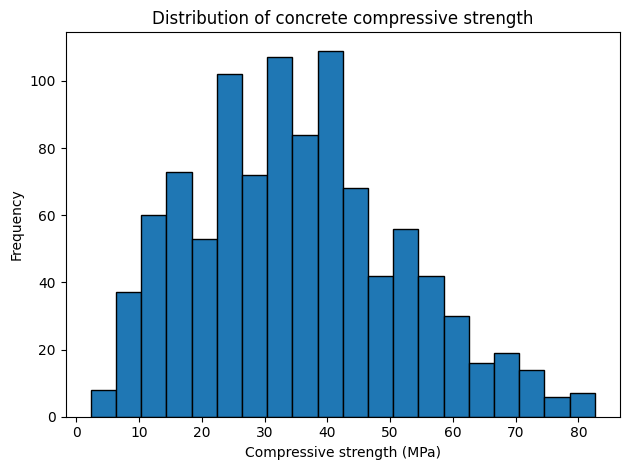

In [15]:

# 7. Define features and target

target_column = "Concrete compressive strength(MPa, megapascals) "

# Cost and emissions are excluded because they are calculated directly
# from the ingredient quantities and would create multicollinearity.
X = data_csv.drop(
    columns=[
        target_column,
        "Cost per m^3",
        "CO2_Emissions"
    ]
)

y = data_csv[target_column]

# 8. Create train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# 9. Train the linear regression model

model = LinearRegression()
model.fit(X_train, y_train)

# 10. Make predictions

y_pred = model.predict(X_test)

# 11. Evaluate the model

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r_squared = r2_score(y_test, y_pred)

print("\nTest-set performance:")
print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r_squared)

# 12. Display regression coefficients

print("\nIntercept:", model.intercept_)

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

print("\nRegression coefficients:")
print(coefficients)

# 13. Five-fold cross-validation

print("\nCross-validation results:")

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    LinearRegression(),
    X,
    y,
    cv=kf,
    scoring="r2"
)

print("R² scores:", scores)
print("Mean R²:", scores.mean())
print("Standard deviation:", scores.std())

# 14. Distribution of compressive strength

plt.hist(
    data_csv[target_column],
    bins=20,
    edgecolor="black"
)

plt.ylabel("Frequency")
plt.xlabel("Compressive strength (MPa)")
plt.title("Distribution of concrete compressive strength")
plt.tight_layout()
plt.show()